# LAB 3 – Bài 6 (Trang 26): Dùng k-Means giảm số màu trong ảnh

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


## 1. Khai báo thư viện

In [2]:
print(f"{HO_TEN} – {MSSV}")
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

Trang Kim Đạt – 6451071018


## 2. Đọc ảnh cần giảm kích thước và hiển thị
Đặt tên file ảnh của bạn vào biến `DUONG_DAN_ANH`. Nếu file không tồn tại, notebook dùng ảnh mẫu `china.jpg` đi kèm thư viện scikit-learn để vẫn chạy được.

Trang Kim Đạt – 6451071018
Dùng ảnh: anh_goc.jpg


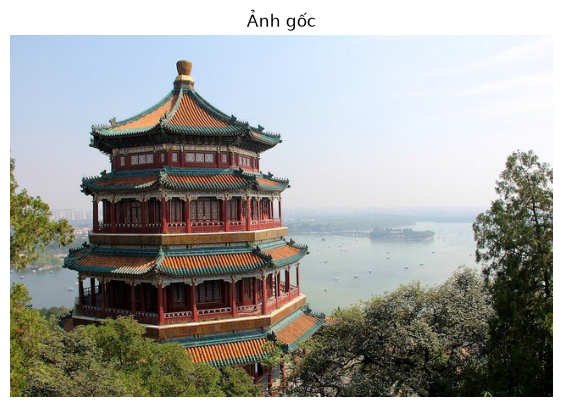

In [3]:
print(f"{HO_TEN} – {MSSV}")
DUONG_DAN_ANH = "anh_goc.jpg"   # <-- thay bằng ảnh của bạn (đặt cùng thư mục với notebook)

if os.path.exists(DUONG_DAN_ANH):
    anh = np.array(Image.open(DUONG_DAN_ANH).convert("RGB"))
    print("Dùng ảnh:", DUONG_DAN_ANH)
else:
    anh = load_sample_image("china.jpg")
    DUONG_DAN_ANH = "anh_goc.jpg"
    Image.fromarray(anh).save(DUONG_DAN_ANH, quality=95)
    print("Không tìm thấy ảnh, dùng ảnh mẫu china.jpg của scikit-learn (đã lưu thành", DUONG_DAN_ANH, ")")

plt.figure(figsize=(7, 5))
plt.imshow(anh); plt.title("Ảnh gốc"); plt.axis("off"); plt.show()

## 3. Chuyển ảnh thành mảng số, lấy chiều rộng / cao

In [ ]:
print(f"{HO_TEN} – {MSSV}")
cao, rong, sau = anh.shape
print("Chiều cao:", cao, "| Chiều rộng:", rong, "| Độ sâu (kênh màu):", sau)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(anh.reshape(-1, 3), axis=0)))

Trang Kim Đạt – 6451071018
Chiều cao: 427 | Chiều rộng: 640 | Độ sâu (kênh màu): 3
Số màu khác nhau trong ảnh gốc: 88933


## 4. Chuẩn hóa màu về [0, 1] và chuyển mảng 3 chiều → 2 chiều (cao × rộng, sâu)

In [5]:
print(f"{HO_TEN} – {MSSV}")
anh_chuan_hoa = anh / 255.0
X = anh_chuan_hoa.reshape(cao * rong, sau)
print("Kích thước mảng 2 chiều:", X.shape)

Trang Kim Đạt – 6451071018
Kích thước mảng 2 chiều: (273280, 3)


## 5. Gom cụm k-Means với số màu mong muốn là 32

In [6]:
print(f"{HO_TEN} – {MSSV}")
SO_MAU = 32
kmeans = KMeans(n_clusters=SO_MAU, n_init=1, random_state=42).fit(X)
nhan = kmeans.labels_
bang_mau = kmeans.cluster_centers_        # 32 màu đại diện
X_nen = bang_mau[nhan]                    # thay mỗi pixel bằng màu tâm cụm của nó
print("Kích thước mảng sau gom cụm:", X_nen.shape, "| số màu:", len(np.unique(X_nen, axis=0)))

Trang Kim Đạt – 6451071018
Kích thước mảng sau gom cụm: (273280, 3) | số màu: 32


## 6. Khôi phục mảng 2 chiều → 3 chiều như ban đầu

In [7]:
print(f"{HO_TEN} – {MSSV}")
anh_nen = X_nen.reshape(cao, rong, sau)
print("Kích thước ảnh khôi phục:", anh_nen.shape)

Trang Kim Đạt – 6451071018
Kích thước ảnh khôi phục: (427, 640, 3)


## 7. Hiển thị ảnh kết quả và so sánh với ảnh gốc

Trang Kim Đạt – 6451071018


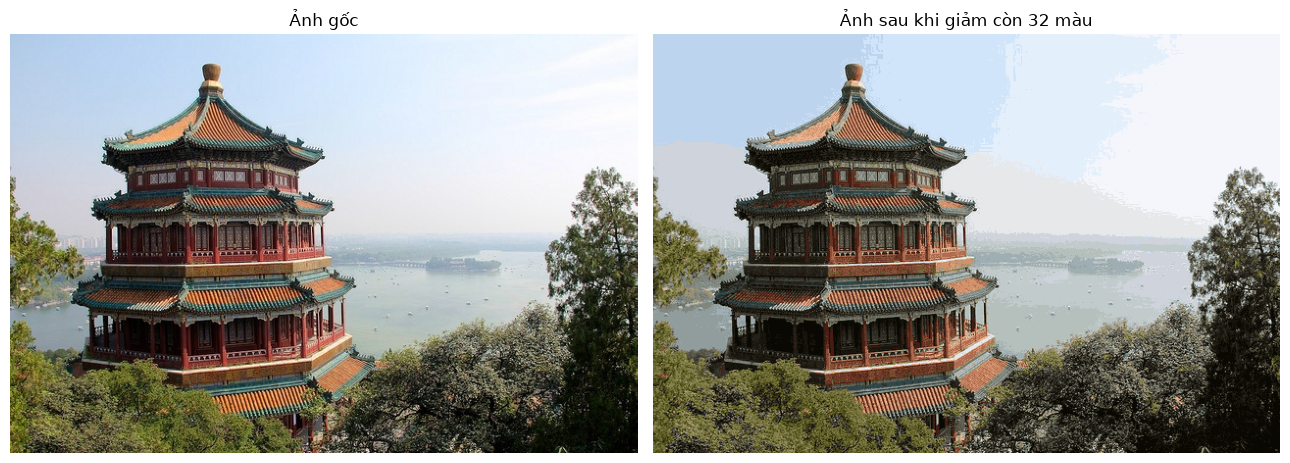

In [8]:
print(f"{HO_TEN} – {MSSV}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(anh); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
axes[1].imshow(anh_nen); axes[1].set_title(f"Ảnh sau khi giảm còn {SO_MAU} màu"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 8. Lưu ảnh kết quả xuống đĩa và so sánh dung lượng
Ảnh sau gom cụm chỉ có 32 màu nên được lưu dạng **bảng màu (palette, 8-bit)**, nhờ đó dung lượng giảm đáng kể so với ảnh 24-bit gốc cùng định dạng PNG.

In [9]:
print(f"{HO_TEN} – {MSSV}")
# Ảnh gốc lưu PNG 24-bit để so sánh công bằng cùng định dạng
Image.fromarray(anh).save("anh_goc.png", optimize=True)

# Ảnh nén: lưu chỉ số màu (palette) + bảng 32 màu
anh_palette = Image.fromarray(nhan.reshape(cao, rong).astype(np.uint8), mode="P")
bang_mau_rgb = np.clip(np.round(bang_mau * 255), 0, 255).astype(np.uint8)
palette = np.zeros((256, 3), dtype=np.uint8)
palette[:SO_MAU] = bang_mau_rgb
anh_palette.putpalette(palette.flatten().tolist())
anh_palette.save(f"anh_{SO_MAU}_mau.png", optimize=True)

kt_goc = os.path.getsize("anh_goc.png")
kt_nen = os.path.getsize(f"anh_{SO_MAU}_mau.png")
print(f"Dung lượng ảnh gốc (PNG 24-bit): {kt_goc / 1024:.1f} KB")
print(f"Dung lượng ảnh {SO_MAU} màu (PNG palette): {kt_nen / 1024:.1f} KB")
print(f"Giảm {100 * (1 - kt_nen / kt_goc):.1f}% dung lượng")

Trang Kim Đạt – 6451071018
Dung lượng ảnh gốc (PNG 24-bit): 468.0 KB
Dung lượng ảnh 32 màu (PNG palette): 75.7 KB
Giảm 83.8% dung lượng


## 9. (Mở rộng) Ảnh hưởng của số màu k đến chất lượng ảnh

Trang Kim Đạt – 6451071018


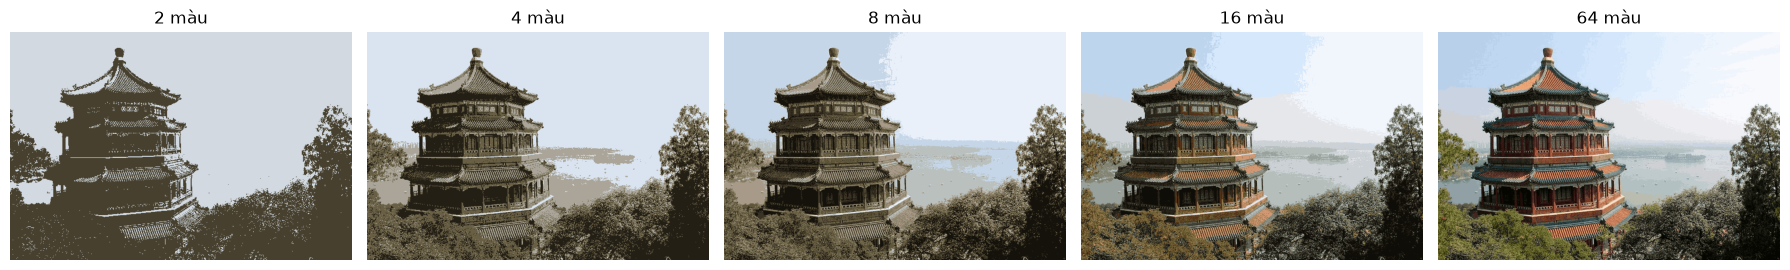

In [10]:
print(f"{HO_TEN} – {MSSV}")
danh_sach_k = [2, 4, 8, 16, 64]
fig, axes = plt.subplots(1, len(danh_sach_k), figsize=(18, 4))
for ax, k in zip(axes, danh_sach_k):
    km = KMeans(n_clusters=k, n_init=1, random_state=42).fit(X)
    ax.imshow(km.cluster_centers_[km.labels_].reshape(cao, rong, sau))
    ax.set_title(f"{k} màu"); ax.axis("off")
plt.tight_layout(); plt.show()